# 04 · LLM-based traffic classification (Llama 3 via Ollama)

Installs Ollama inside Colab, pulls **Llama 3 (8B)** and asks it to label every window in `dataset.json` as `normal` or `zararli` (malicious) with three prompt designs:

1. **Zero-shot, short** — one-line instruction
2. **Zero-shot, long** — analyst persona + explicit rules (port scan, ARP/DNS spoofing, normal web traffic)
3. **Few-shot** — two labelled examples (normal HTTPS vs. port scan)

Each run is scored with accuracy, precision, recall and F1 (malicious = positive class) and a confusion matrix. Requires a GPU runtime.


In [3]:
import os
import subprocess
import time

print("1. Gerekli paketler kontrol ediliyor/kuruluyor...")
os.system("apt-get install -y zstd")

print("2. Ollama kuruluyor...")
os.system("curl -fsSL https://ollama.com/install.sh | sh")

print("3. Ollama sunucusu arka planda başlatılıyor...")
subprocess.Popen(["ollama", "serve"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
time.sleep(5)

print("4. Llama3 modeli indiriliyor (Bekleyin)...")
subprocess.run(["ollama", "pull", "llama3"])

print("\n✅ KURULUM TAMAMLANDI! Artık sınıflandırma kodunu çalıştırabilirsin.")

Toplam 167 ağ trafiği örneği test ediliyor...

İlerleme: 10/167 örnek işlendi.
İlerleme: 20/167 örnek işlendi.
İlerleme: 30/167 örnek işlendi.
İlerleme: 40/167 örnek işlendi.
İlerleme: 50/167 örnek işlendi.
İlerleme: 60/167 örnek işlendi.
İlerleme: 70/167 örnek işlendi.
İlerleme: 80/167 örnek işlendi.
İlerleme: 90/167 örnek işlendi.
İlerleme: 100/167 örnek işlendi.
İlerleme: 110/167 örnek işlendi.
İlerleme: 120/167 örnek işlendi.
İlerleme: 130/167 örnek işlendi.
İlerleme: 140/167 örnek işlendi.
İlerleme: 150/167 örnek işlendi.
İlerleme: 160/167 örnek işlendi.
İlerleme: 167/167 örnek işlendi.

=============== Zero-Shot (Kısa Prompt) Sonuçları ===============
Accuracy (Doğruluk)  : %41.32
Precision (Kesinlik) : %33.33
Recall (Duyarlılık)  : %96.00
F1-Score             : %49.48


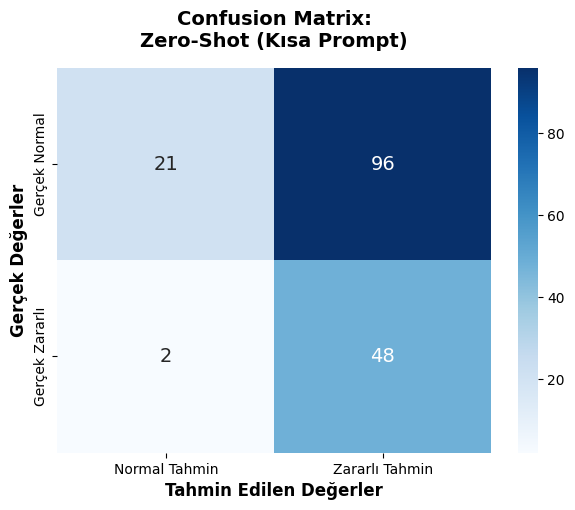


=============== Zero-Shot (Uzun Prompt) Sonuçları ===============
Accuracy (Doğruluk)  : %31.14
Precision (Kesinlik) : %30.06
Recall (Duyarlılık)  : %98.00
F1-Score             : %46.01


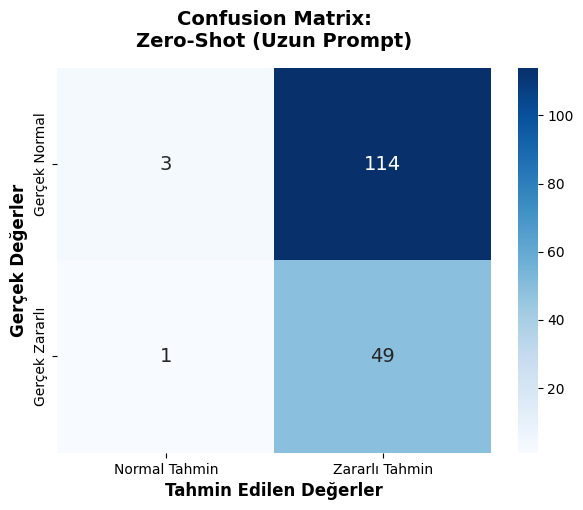


=============== Few-Shot (Örnekli Prompt) Sonuçları ===============
Accuracy (Doğruluk)  : %36.53
Precision (Kesinlik) : %31.58
Recall (Duyarlılık)  : %96.00
F1-Score             : %47.52


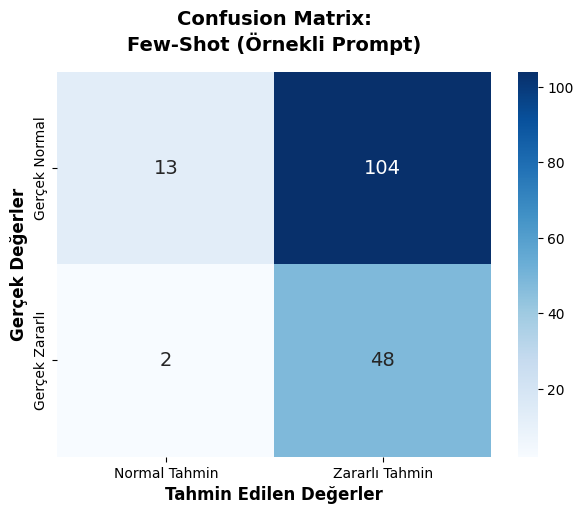

In [4]:
import json
import requests
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

OLLAMA_URL = "http://localhost:11434/api/generate"
MODEL_NAME = "llama3"

def query_ollama(prompt):
    payload = {
        "model": MODEL_NAME,
        "prompt": prompt,
        "stream": False
    }
    try:
        response = requests.post(OLLAMA_URL, json=payload)
        if response.status_code == 200:
            cevap = response.json().get("response", "").strip().lower()
            if "zararli" in cevap or "zararlı" in cevap:
                return "zararli"
            else:
                return "normal"
    except Exception as e:
        print(f"Bağlantı hatası: {e}")
    return "hata"

def evaluate_predictions_detailed(y_true, y_pred, experiment_name):
    # TP: Gerçekte zararlı, model de "zararlı" dedi
    # TN: Gerçekte normal, model de "normal" dedi
    # FP: Gerçekte normal, model "zararlı" dedi (Yanlış Alarm)
    # FN: Gerçekte zararlı, model "normal" dedi (Kaçırılan Saldırı)

    TP = sum(1 for t, p in zip(y_true, y_pred) if t == "zararli" and p == "zararli")
    TN = sum(1 for t, p in zip(y_true, y_pred) if t == "normal" and p == "normal")
    FP = sum(1 for t, p in zip(y_true, y_pred) if t == "normal" and p == "zararli")
    FN = sum(1 for t, p in zip(y_true, y_pred) if t == "zararli" and p == "normal")

    # Metrik Hesaplamaları
    accuracy = (TP + TN) / len(y_true) if len(y_true) > 0 else 0
    precision = TP / (TP + FP) if (TP + FP) > 0 else 0
    recall = TP / (TP + FN) if (TP + FN) > 0 else 0
    f1_score = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

    # Metin olarak konsola yazdırma
    print(f"\n{'='*15} {experiment_name} Sonuçları {'='*15}")
    print(f"Accuracy (Doğruluk)  : %{accuracy * 100:.2f}")
    print(f"Precision (Kesinlik) : %{precision * 100:.2f}")
    print(f"Recall (Duyarlılık)  : %{recall * 100:.2f}")
    print(f"F1-Score             : %{f1_score * 100:.2f}")
    print("=" * 55)

    # --- GÖRSEL OLARAK CONFUSION MATRIX ÇİZİMİ ---

    # Matris verisini oluşturuyoruz:
    # [ [Gerçek Normal & Tahmin Normal (TN), Gerçek Normal & Tahmin Zararlı (FP)],
    #   [Gerçek Zararlı & Tahmin Normal (FN), Gerçek Zararlı & Tahmin Zararlı (TP)] ]
    cm = np.array([[TN, FP],
                   [FN, TP]])

    # Grafik boyutunu ayarlıyoruz
    plt.figure(figsize=(7, 5))

    # Seaborn ile ısı haritası (heatmap) oluşturuyoruz
    # 'Blues' renk paleti gönderdiğin görseldeki gibi mavi tonlarını kullanır
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Normal Tahmin', 'Zararlı Tahmin'],
                yticklabels=['Gerçek Normal', 'Gerçek Zararlı'],
                annot_kws={"size": 14}) # Rakamların boyutunu biraz büyütüyoruz

    # Eksen etiketleri ve başlık
    plt.ylabel('Gerçek Değerler', fontsize=12, fontweight='bold')
    plt.xlabel('Tahmin Edilen Değerler', fontsize=12, fontweight='bold')
    plt.title(f'Confusion Matrix:\n{experiment_name}', fontsize=14, fontweight='bold', pad=15)

    # Grafiği ekranda göster
    plt.show()


# ---------------- PROMPT TASARIMLARI ----------------
def prompt_zeroshot_kisa(trafik_verisi):
    return f"""Aşağıdaki ağ trafiği normal mi yoksa zararli mi? Sadece 'normal' veya 'zararli' yaz.
    Veri: {json.dumps(trafik_verisi, ensure_ascii=False)}"""

def prompt_zeroshot_uzun(trafik_verisi):
    return f"""Sen uzman bir siber güvenlik analistisin. Görevin, verilen ağ trafiği özetini inceleyerek anormallikleri tespit etmektir.
    - Eğer çok kısa sürede tek bir kaynaktan farklı portlara ardışık istekler varsa bu bir Port Taramasıdır (zararli).
    - Eğer çok fazla ARP veya DNS yanıtı manipülasyonu varsa bu Spoofing'dir (zararli).
    - Eğer standart web gezintisi (HTTP/HTTPS, 80/443) ve DNS sorguları mantıklı bir akışlaysa (normal).

    Aşağıdaki veri 'normal' mi yoksa 'zararli' mi? Sadece tek kelime ile cevap ver.
    Veri: {json.dumps(trafik_verisi, ensure_ascii=False)}"""

def prompt_fewshot(trafik_verisi):
    return f"""Görevin ağ trafiğini sınıflandırmaktır. İşte bazı örnekler:

    Örnek 1:
    Veri: {{"genel_ozet": {{"paket_sayisi": 5, "protokoller": ["TCP"]}}, "gozlemlenen_davranis_oruntuleri": ["[0.1s] 192.168.1.5 -> 8.8.8.8 | Protokol: TCP | Port: 54321->443 | TCP Flags: 0x0002"]}}
    Karar: normal

    Örnek 2:
    Veri: {{"genel_ozet": {{"paket_sayisi": 150, "protokoller": ["TCP"]}}, "gozlemlenen_davranis_oruntuleri": ["[0.1s] 10.0.0.5 -> 10.0.0.6 | Port: 12345->21", "[0.2s] 10.0.0.5 -> 10.0.0.6 | Port: 12345->22", "[0.3s] 10.0.0.5 -> 10.0.0.6 | Port: 12345->23"]}}
    Karar: zararli

    Şimdi aşağıdaki veriyi sınıflandır. Sadece 'normal' veya 'zararli' yaz.
    Veri: {json.dumps(trafik_verisi, ensure_ascii=False)}"""


# ---------------- ANA ÇALIŞTIRMA BLOĞU ----------------
if __name__ == "__main__":
    try:
        with open("dataset.json", "r", encoding="utf-8") as f:
            veri_seti = json.load(f)

        gercek_etiketler = [veri["etiket"] for veri in veri_seti]

        tahminler_zs_kisa = []
        tahminler_zs_uzun = []
        tahminler_fewshot = []

        print(f"Toplam {len(veri_seti)} ağ trafiği örneği test ediliyor...\n")

        for idx, veri in enumerate(veri_seti):
            test_verisi = {
                "genel_ozet": veri.get("genel_ozet", {}),
                "gozlemlenen_davranis_oruntuleri": veri.get("gozlemlenen_davranis_oruntuleri", [])
            }

            tahminler_zs_kisa.append(query_ollama(prompt_zeroshot_kisa(test_verisi)))
            tahminler_zs_uzun.append(query_ollama(prompt_zeroshot_uzun(test_verisi)))
            tahminler_fewshot.append(query_ollama(prompt_fewshot(test_verisi)))

            if (idx + 1) % 10 == 0 or (idx + 1) == len(veri_seti):
                print(f"İlerleme: {idx+1}/{len(veri_seti)} örnek işlendi.")

        evaluate_predictions_detailed(gercek_etiketler, tahminler_zs_kisa, "Zero-Shot (Kısa Prompt)")
        evaluate_predictions_detailed(gercek_etiketler, tahminler_zs_uzun, "Zero-Shot (Uzun Prompt)")
        evaluate_predictions_detailed(gercek_etiketler, tahminler_fewshot, "Few-Shot (Örnekli Prompt)")

    except FileNotFoundError:
        print("HATA: 'dataset.json' dosyası bulunamadı! Lütfen dosyayı Colab ortamına yüklediğinden emin ol.")